PyTorch Version: 2.14.1+cu130 | Wybrane urządzenie: cuda


100%|██████████| 170M/170M [17:30<00:00, 162kB/s]


Liczba klas: 10 (['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'])
Próbki treningowe: 50000 | Próbki testowe: 10000
Liczba parametrów MLP: 1,707,274
Liczba parametrów CNN: 1,117,354

=== Trening: MLP (Baseline) ===
  Epoka  1/10 | Test Accuracy: 47.33%
  Epoka  2/10 | Test Accuracy: 48.90%
  Epoka  3/10 | Test Accuracy: 50.25%
  Epoka  4/10 | Test Accuracy: 51.23%
  Epoka  5/10 | Test Accuracy: 53.30%
  Epoka  6/10 | Test Accuracy: 52.43%
  Epoka  7/10 | Test Accuracy: 52.47%
  Epoka  8/10 | Test Accuracy: 52.55%
  Epoka  9/10 | Test Accuracy: 52.35%
  Epoka 10/10 | Test Accuracy: 53.23%

=== Trening: SimpleCNN ===
  Epoka  1/10 | Test Accuracy: 64.02%
  Epoka  2/10 | Test Accuracy: 70.84%
  Epoka  3/10 | Test Accuracy: 72.09%
  Epoka  4/10 | Test Accuracy: 74.38%
  Epoka  5/10 | Test Accuracy: 69.03%
  Epoka  6/10 | Test Accuracy: 76.20%
  Epoka  7/10 | Test Accuracy: 77.25%
  Epoka  8/10 | Test Accuracy: 78.13%
  Epoka  9/10 | Test Accuracy: 

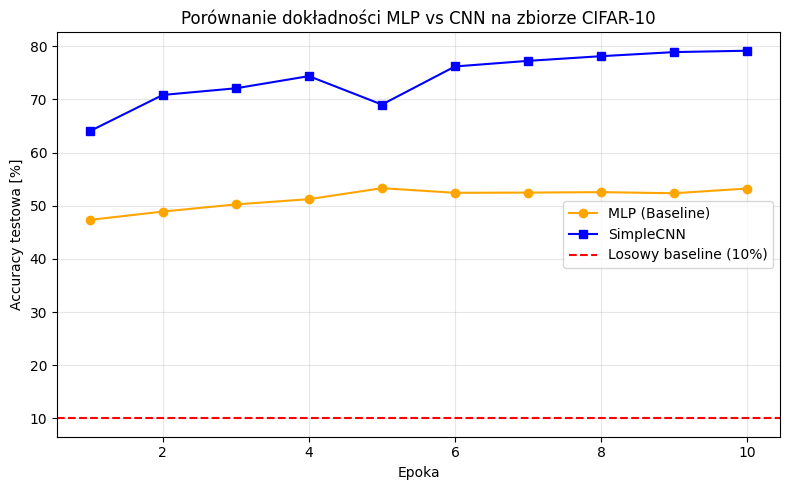

In [1]:
#Instalacja zależności i wybór urządzenia (GPU/CPU)

import time
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms

# Ustawienie ziarna dla powtarzalności wyników
torch.manual_seed(0)

# Sprawdzenie dostępności GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version: {torch.__version__} | Wybrane urządzenie: {device}")



#Przygotowanie danych (CIFAR-10)

# Średnie i odchylenia standardowe dla 3 kanałów RGB
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Pobranie zbioru treningowego i testowego
train_ds = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
test_ds = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

classes = train_ds.classes
print(f"Liczba klas: {len(classes)} ({classes})")
print(f"Próbki treningowe: {len(train_ds)} | Próbki testowe: {len(test_ds)}")

# DataLoadery
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2)



#Definicja architektury modeli (MLP vs CNN)

class MLP(nn.Module):
    """Wielowarstwowy Perceptron (MLP) dla obrazów CIFAR-10 (3x32x32 = 3072 wejść)."""
    def __init__(self, in_dim=3*32*32, hidden=(512, 256), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]),
            nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]),
            nn.ReLU(),
            nn.Linear(hidden[1], n_classes)
        )

    def forward(self, x):
        return self.net(x)


class SimpleCNN(nn.Module):
    "Prosta Sieć Splotowa (CNN) z blokami Conv2D-BatchNorm-ReLU-MaxPool."
    def __init__(self, n_classes=10):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.Conv2d(cout, cout, kernel_size=3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2)
            )

        # 32x32x3 -> 16x16x32 -> 8x8x64
        self.features = nn.Sequential(
            block(3, 32),
            block(32, 64)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, n_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    "Zwraca całkowitą liczbę uczalnych parametrów w modelu."
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

mlp_model = MLP()
cnn_model = SimpleCNN()

print(f"Liczba parametrów MLP: {count_params(mlp_model):,}")
print(f"Liczba parametrów CNN: {count_params(cnn_model):,}")


# SEKCJA 3: Pętla uczenia i ewaluacji
def evaluate(model, data_loader):
    "Oblicza dokładność (accuracy) modelu na podanym DataLoaderze."
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for xb, yb in data_loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb).argmax(dim=1)
            correct += (preds == yb).sum().item()
            total += yb.numel()
    return correct / total


def train_model(model, epochs=10, lr=1e-3):
    "Trenuje model przez podaną liczbę epok i mierzy czas uczenia."
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    acc_history = []
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        test_acc = evaluate(model, test_dl)
        acc_history.append(test_acc)
        print(f"  Epoka {epoch:2d}/{epochs} | Test Accuracy: {test_acc * 100:.2f}%")

    total_time = time.time() - start_time
    return acc_history, total_time

#Przeprowadzenie treningu porównawczego
EPOCHS = 10
LR = 0.001

print("\n=== Trening: MLP (Baseline) ===")
mlp_acc, mlp_time = train_model(MLP(), epochs=EPOCHS, lr=LR)

print("\n=== Trening: SimpleCNN ===")
cnn_acc, cnn_time = train_model(SimpleCNN(), epochs=EPOCHS, lr=LR)


#Zestawienie wyników i generowanie wykresu

print("\n" + "="*50)
print(f"{'Model':<8} | {'Parametry':>12} | {'Best Acc [%]':>12} | {'Czas [s]':>9}")
print("-" * 50)
print(f"{'MLP':<8} | {count_params(mlp_model):>12,} | {max(mlp_acc)*100:>12.2f} | {mlp_time:>9.1f}")
print(f"{'CNN':<8} | {count_params(cnn_model):>12,} | {max(cnn_acc)*100:>12.2f} | {cnn_time:>9.1f}")
print("="*50)

# Generowanie wykresu accuracy
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), [a * 100 for a in mlp_acc], "o-", label="MLP (Baseline)", color="orange")
plt.plot(range(1, EPOCHS + 1), [a * 100 for a in cnn_acc], "s-", label="SimpleCNN", color="blue")
plt.axhline(y=10.0, color="r", linestyle="--", label="Losowy baseline (10%)")
plt.xlabel("Epoka")
plt.ylabel("Accuracy testowa [%]")
plt.title("Porównanie dokładności MLP vs CNN na zbiorze CIFAR-10")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("porownanie_accuracy.png", dpi=300)
plt.show()